## Week 8: K-Nearest Neighbors

This week I am going to be using k-nearest neighbors to see how the data is clustered near each other. I will be first using the base model to see how it performs and then will hyperparameter tune it to compare the performance. 

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve, auc

In [3]:
model = KNeighborsClassifier()

params = {'n_neighbors' : range(1, 21, 2), 'weights' : ['uniform', 'distance'], 'p' : [1, 2]}

random_search = RandomizedSearchCV(model, params, cv = 5, n_iter = 30)

### Dataset 1: Instacart Dataset

In [4]:
data1 = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/instacart.csv')

transform_cols = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase']

for col in transform_cols:
    data1[f'log_{col}'] = np.log1p(data1[col])

data1_transformed = data1.drop(columns = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase'])

data1_transformed.head()

,user_id,product_id,ordered,log_times_purchased,log_num_orders,log_frequency,log_Product Popularity,log_Last Product Order,log_Last Order,log_Orders Since Last Purchase
0,71,45,0.0,1.791759,3.178054,0.196710,0.005878,2.302585,3.178054,2.708050
1,71,117,1.0,2.995732,3.178054,0.602175,0.001219,3.178054,3.178054,0.000000
2,71,2078,0.0,0.693147,3.178054,0.042560,0.006478,1.386294,3.178054,3.044522
3,71,2825,0.0,1.098612,3.178054,0.083382,0.003743,1.945910,3.178054,2.890372
4,71,3376,1.0,1.098612,3.178054,0.083382,0.003602,2.995732,3.178054,1.609438


In [5]:
X = data1_transformed.drop(columns = ['ordered', 'user_id', 'product_id'])
y = data1_transformed['ordered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [6]:
model.fit(X_train, y_train)

y_preds = model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.000,0.041,0.650
2,0.000,0.040,0.636
3,0.000,0.042,0.665
4,0.000,0.035,0.552
5,0.000,0.042,0.654
6,0.000,0.041,0.652
7,0.000,0.043,0.673
8,0.051,0.057,0.895
9,0.200,0.109,1.715


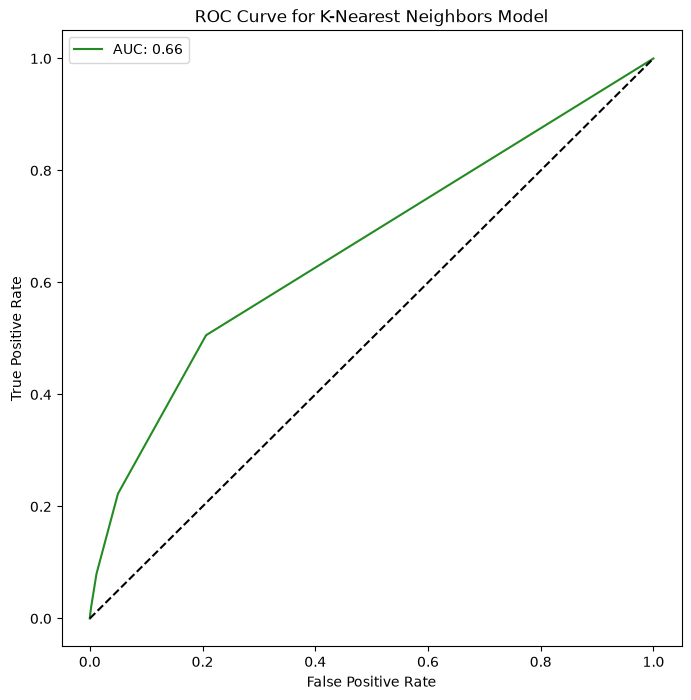

In [11]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [ ]:
random_search.fit(X_train, y_train)

print(f'The best hyperparameters for this dataset is {random_search.best_params_}')

In [ ]:
best_model = KNeighborsClassifier()

best_model.fit(X_train, y_train)

y_preds = best_model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

### Dataset 2: Amazon Reviews Dataset

In [ ]:
import ast
from sklearn.preprocessing import MultiLabelBinarizer

small_reviews = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_reviews%5B1%5D.csv')

small_meta = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_meta%5B1%5D.csv')

small_meta = small_meta.set_index(keys = 'parent_asin')

small_meta = small_meta.drop(columns = ['title', 'images'])

data2 = small_reviews.join(small_meta, on = 'parent_asin', how = 'inner')

data2 = data2.drop(columns = ['main_category', 'store', 'rating_number', 'videos', 'images', 'subtitle', 'author', 'bought_together', 'features', 'description', 'details', 'timestamp', 'text', 'title'])

data2['product_review_count'] = data2.groupby('asin').transform('size')
data2['user_review_count'] = data2.groupby('user_id').transform('size')

data2['price'] = data2['price'].fillna(data2['price'].median())

data2['categories'] = data2['categories'].apply(ast.literal_eval)

mlb = MultiLabelBinarizer()

categories = pd.DataFrame(mlb.fit_transform(data2['categories']), columns = mlb.classes_, index = data2.index)

top_30 = categories.sum().sort_values(ascending = False).head(31).index

categories = categories[top_30[1:31]]

data2 = data2.drop(columns = 'categories')

data2 = data2.join(categories)

columns_to_transform = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count']

for col in columns_to_transform:
    data2[f'log_{col}'] = np.log1p(data2[col])

data2_transformed = data2.drop(columns = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count'])

data2_transformed = data2_transformed.reset_index(drop = True)

for i in range(len(data2_transformed)):
    if data2_transformed.iloc[i]['rating'] == 4:
        data2_transformed.loc[i, 'liked'] = 1
    elif data2_transformed.iloc[i]['rating'] == 5:
        data2_transformed.loc[i, 'liked'] = 1
    else:
        data2_transformed.loc[i, 'liked'] = 0

X = data2_transformed.drop(columns = ['asin', 'parent_asin', 'user_id', 'liked', 'rating'])
y = data2_transformed['liked']

X.head()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [ ]:
model.fit(X_train, y_train)

y_preds = model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [ ]:
random_search.fit(X_train, y_train)

print(f'The best hyperparameters for this dataset is {random_search.best_params_}')

In [ ]:
best_model = KNeighborsClassifier()

best_model.fit(X_train, y_train)

y_preds = best_model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

## Conclusion

